In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from IPython.display import display


from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso

from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report

from mlxtend.plotting import plot_decision_regions

In [2]:
df = pd.read_csv("sleep_debt_screen_time.csv", index_col="user_id")
df.sample(5)

,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
user_id,,,,,,,,,,,,,,,,,,,,,
3494,22,Female,Intermediate,Freelancer,22.90,28,Messaging,80,False,77,...,69.3,18.4,26.1,7.44,15.0,17.7,5,78.9,4.67,Mild
1807,30,Female,Early Bird,Professional,22.73,48,Short-Form Video,77,True,101,...,58.3,29.6,30.0,6.38,15.4,16.1,2,87.0,4.41,Mild
912,30,Male,Early Bird,Student,22.80,32,Short-Form Video,45,False,180,...,70.1,39.7,37.8,6.09,18.2,19.4,2,85.2,5.31,Mild
7290,27,Male,Intermediate,Student,21.38,41,Social Media,69,False,38,...,68.4,32.6,26.4,6.43,18.2,16.7,1,84.6,4.75,Mild
1514,16,Non-Binary,Early Bird,Student,22.53,111,News,63,True,63,...,65.2,30.6,29.3,8.28,19.6,18.6,2,87.4,2.92,No Debt


In [3]:
df.isna().sum()

age                           0
gender                        0
chronotype                    0
occupation                    0
bedtime_hour                  0
screen_time_before_bed_min    0
primary_app_category          0
screen_brightness_pct         0
blue_light_filter_on          0
caffeine_intake_mg            0
caffeine_last_hour            0
physical_activity_min         0
room_temperature_f            0
ambient_noise_db              0
sleep_onset_latency_min       0
total_sleep_hours             0
rem_sleep_pct                 0
deep_sleep_pct                0
awakenings_count              0
sleep_efficiency_pct          0
next_day_fatigue_score        0
sleep_debt_category           0
dtype: int64

In [4]:
# for col in df.columns:
#     print(col)
#     print(df[col].unique())
#     print()

# Regression - target: `next_day_fatigue_score`

In [5]:
dict(df.dtypes)

{'age': dtype('int64'),
 'gender': dtype('O'),
 'chronotype': dtype('O'),
 'occupation': dtype('O'),
 'bedtime_hour': dtype('float64'),
 'screen_time_before_bed_min': dtype('int64'),
 'primary_app_category': dtype('O'),
 'screen_brightness_pct': dtype('int64'),
 'blue_light_filter_on': dtype('bool'),
 'caffeine_intake_mg': dtype('int64'),
 'caffeine_last_hour': dtype('float64'),
 'physical_activity_min': dtype('int64'),
 'room_temperature_f': dtype('float64'),
 'ambient_noise_db': dtype('float64'),
 'sleep_onset_latency_min': dtype('float64'),
 'total_sleep_hours': dtype('float64'),
 'rem_sleep_pct': dtype('float64'),
 'deep_sleep_pct': dtype('float64'),
 'awakenings_count': dtype('int64'),
 'sleep_efficiency_pct': dtype('float64'),
 'next_day_fatigue_score': dtype('float64'),
 'sleep_debt_category': dtype('O')}

In [6]:
target = "next_day_fatigue_score"
num_features = [col for col, dtype in df.dtypes.items() if (dtype in [int, float]) and (col != target)]
print(num_features)
df_num = df.loc[:, num_features]
# sns.pairplot(data=df_num)

['bedtime_hour', 'caffeine_last_hour', 'room_temperature_f', 'ambient_noise_db', 'sleep_onset_latency_min', 'total_sleep_hours', 'rem_sleep_pct', 'deep_sleep_pct', 'sleep_efficiency_pct']


<Axes: >

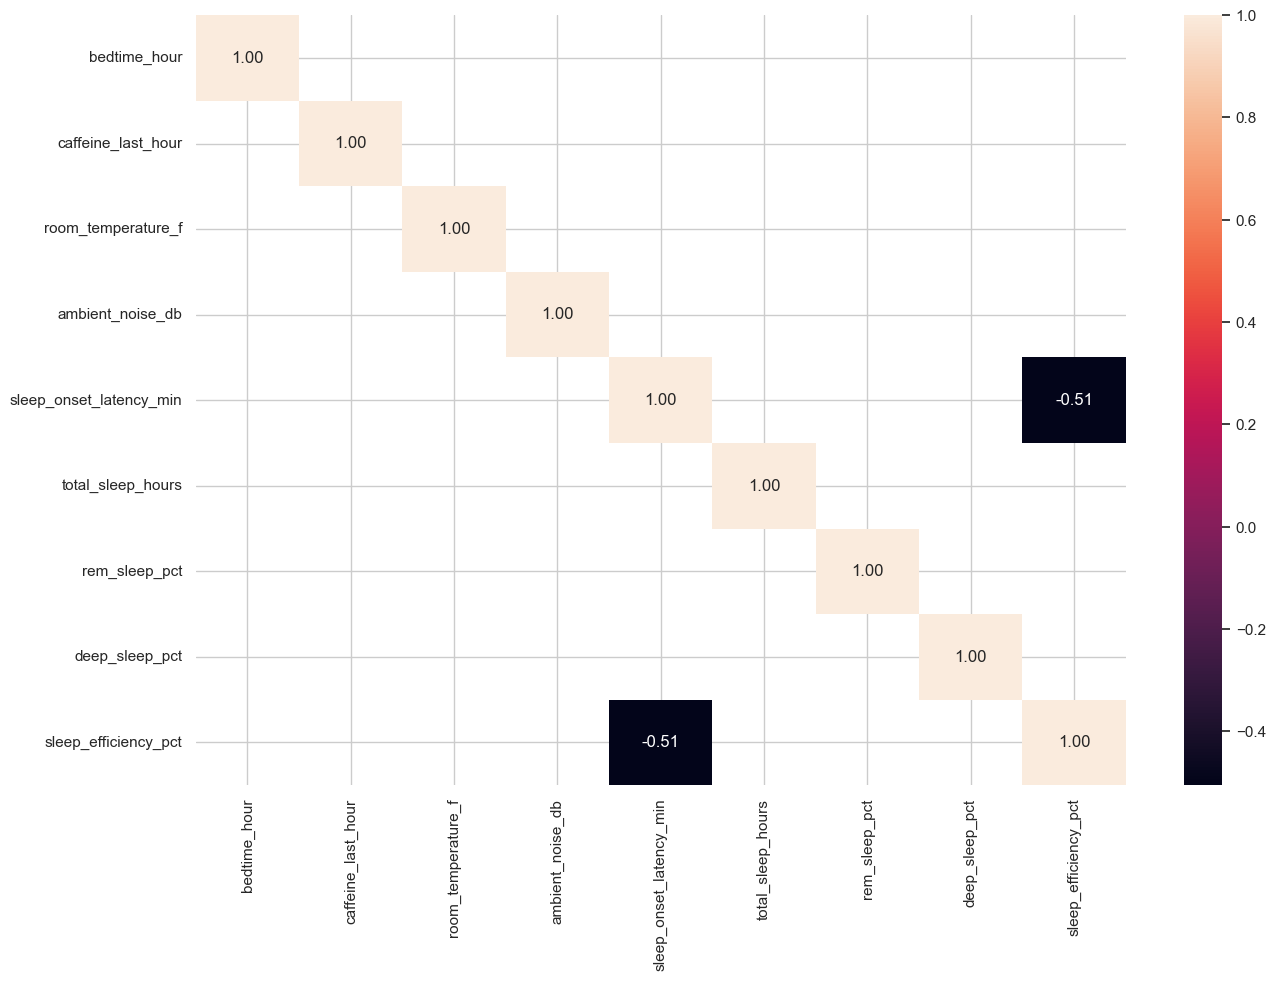

In [7]:
corr_mat = df_num.corr()
mask = abs(corr_mat) >= 0.5

plt.figure(figsize=(15, 10))
sns.heatmap(corr_mat[mask], annot=True, fmt=".2f")

# multiple linear regression

In [8]:
target = "next_day_fatigue_score"
num_features = [col for col, dtype in df.dtypes.items() if (dtype in [int, float]) and (col != target)]

X = df.loc[:, num_features].values
y = df.loc[:, target].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)

r2_train = r2_score(y_train, model.predict(X_train))
r2_test = r2_score(y_test, model.predict(X_test))

print(f"R^2 (train): {r2_train:.3f}")
print(f"R^2 (test): {r2_test:.3f}")

R^2 (train): 0.753
R^2 (test): 0.747


# lasso regression - L1 regularization

In [9]:
alphas = [0.0001, 0.001, 0.01, 0.1]
coefs = []
for alpha in alphas:
    model = Lasso(alpha=alpha)
    model.fit(X_train, y_train)

    # r2_train = r2_score(y_train, model.predict(X_train))
    # r2_test = r2_score(y_test, model.predict(X_test))

    # print(f"alpha={alpha}")
    # print(f"R^2 (train): {r2_train:.3f}", end=", ")
    # print(f"R^2 (test): {r2_test:.3f}")
    # print(model.coef_.flatten(), model.intercept_)
    # print()
    coefs.append(model.coef_)

coef_df = pd.DataFrame(np.array(coefs).T, columns=alphas, index=num_features)
coef_df

,0.0001,0.0010,0.0100,0.1000
bedtime_hour,0.004181,0.003095,0.000000,-0.000000
caffeine_last_hour,0.010484,0.009819,0.003231,0.000000
room_temperature_f,-0.014231,-0.013302,-0.003867,-0.000000
ambient_noise_db,-0.016645,-0.015608,-0.005005,-0.000000
sleep_onset_latency_min,0.120051,0.119774,0.116370,0.095777
total_sleep_hours,-0.601191,-0.600145,-0.591853,-0.512984
rem_sleep_pct,-0.174740,-0.174313,-0.169864,-0.105878
deep_sleep_pct,-0.023352,-0.022811,-0.017236,-0.000000
sleep_efficiency_pct,-0.349515,-0.349014,-0.343891,-0.290089


In [10]:
coef_df[0.1]

bedtime_hour              -0.000000
caffeine_last_hour         0.000000
room_temperature_f        -0.000000
ambient_noise_db          -0.000000
sleep_onset_latency_min    0.095777
total_sleep_hours         -0.512984
rem_sleep_pct             -0.105878
deep_sleep_pct            -0.000000
sleep_efficiency_pct      -0.290089
Name: 0.1, dtype: float64

In [11]:
features = coef_df[coef_df[0.1] != 0].index

target = "next_day_fatigue_score"

X = df.loc[:, features].values
y = df.loc[:, target].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)

r2_train = r2_score(y_train, model.predict(X_train))
r2_test = r2_score(y_test, model.predict(X_test))

print(f"R^2 (train): {r2_train:.3f}")
print(f"R^2 (test): {r2_test:.3f}")

R^2 (train): 0.752
R^2 (test): 0.745


In [12]:
len(features)

4

## using one numeric feature (`total_sleep_hours`) and one categorical feature (`primary_app_category`)

In [13]:
df["primary_app_category"].unique()

array(['Social Media', 'Short-Form Video', 'Messaging', 'Streaming',
       'E-Reading', 'Gaming', 'News'], dtype=object)

In [14]:
df["primary_app_category"].value_counts()

primary_app_category
Short-Form Video    2468
Social Media        1834
Streaming           1193
Gaming               882
Messaging            753
E-Reading            711
News                 659
Name: count, dtype: int64

In [15]:
features = ["total_sleep_hours", "primary_app_category"]
target = "next_day_fatigue_score"

ohe = OneHotEncoder(sparse_output=False)
X_cat = ohe.fit_transform(df.loc[:, ["primary_app_category"]])
X_num = df.loc[:, ["total_sleep_hours"]].values


y = df.loc[:, [target]].values

X_cat_train, X_cat_test, X_num_train, X_num_test, y_train, y_test = train_test_split(X_cat, X_num, y, test_size=0.3, random_state=42)

sc = StandardScaler()
X_num_train = sc.fit_transform(X_num_train)
X_num_test = sc.transform(X_num_test)

X_train = np.column_stack((X_cat_train, X_num_train))
X_test = np.column_stack((X_cat_test, X_num_test))


model = LinearRegression()
model.fit(X_train, y_train)

r2_train = r2_score(y_train, model.predict(X_train))
r2_test = r2_score(y_test, model.predict(X_test))

print(f"R^2 (train): {r2_train:.3f}")
print(f"R^2 (test): {r2_test:.3f}")

R^2 (train): 0.533
R^2 (test): 0.528


In [16]:
alphas = [0.0001, 0.001, 0.01, 0.05]
coefs = []
for alpha in alphas:
    model = Lasso(alpha=alpha)
    model.fit(X_train, y_train)

    r2_train = r2_score(y_train, model.predict(X_train))
    r2_test = r2_score(y_test, model.predict(X_test))

    print(f"alpha={alpha}")
    print(f"R^2 (train): {r2_train:.3f}", end=", ")
    print(f"R^2 (test): {r2_test:.3f}")
    print(model.coef_.flatten(), model.intercept_)
    print()
    coefs.append(model.coef_)

coef_df = pd.DataFrame(np.array(coefs), index=alphas, columns=list(ohe.categories_[0]) + ["total_sleep_hours"]).rename_axis("alphas").round(3)
coef_df

alpha=0.0001
R^2 (train): 0.534, R^2 (test): 0.528
[-0.50238802  0.20417649 -0.         -0.16835931  0.30260412  0.16212406
 -0.09816135 -0.66886145] [4.48546782]

alpha=0.001
R^2 (train): 0.533, R^2 (test): 0.528
[-0.49187255  0.19526665 -0.         -0.15615388  0.29935092  0.15771621
 -0.09195581 -0.66771733] [4.4856165]

alpha=0.01
R^2 (train): 0.528, R^2 (test): 0.527
[-0.38511852  0.10772677 -0.         -0.03256972  0.26824135  0.11498691
 -0.02859831 -0.65627583] [4.48580124]

alpha=0.05
R^2 (train): 0.480, R^2 (test): 0.485
[-0.          0.         -0.         -0.          0.07832075  0.
 -0.         -0.61078522] [4.5385477]



,E-Reading,Gaming,Messaging,News,Short-Form Video,Social Media,Streaming,total_sleep_hours
alphas,,,,,,,,
0.0001,-0.502,0.204,-0.0,-0.168,0.303,0.162,-0.098,-0.669
0.0010,-0.492,0.195,-0.0,-0.156,0.299,0.158,-0.092,-0.668
0.0100,-0.385,0.108,-0.0,-0.033,0.268,0.115,-0.029,-0.656
0.0500,-0.000,0.000,-0.0,-0.000,0.078,0.000,-0.000,-0.611


In [17]:
list(ohe.categories_[0]) + ["total_sleep_hours"]

['E-Reading',
 'Gaming',
 'Messaging',
 'News',
 'Short-Form Video',
 'Social Media',
 'Streaming',
 'total_sleep_hours']

In [18]:
coef_df.loc[0.0100, list(ohe.categories_[0])].sort_values(key=abs, ascending=False)

E-Reading          -0.385
Short-Form Video    0.268
Social Media        0.115
Gaming              0.108
News               -0.033
Streaming          -0.029
Messaging          -0.000
Name: 0.01, dtype: float64

In [19]:
df["primary_app_category"].value_counts()

primary_app_category
Short-Form Video    2468
Social Media        1834
Streaming           1193
Gaming               882
Messaging            753
E-Reading            711
News                 659
Name: count, dtype: int64